# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2025-11-05
> - Modified: 2026-01-03
---

> - [PBMC Profiling from a Healthy Donor](https://www.parsebiosciences.com/datasets/pbmc-profiling-from-a-healthy-donor)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - Parse Biosciences
---

# Experimental Design

> - Evercode™ Whole Transcriptome products (Evercode WT v1)

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donor | PBMCs | Peripheral blood mononuclear cells | - | - | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_ParseBiosciences/Hs_PBMCs_Parse"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
# dir.create(file.path(data_dir, "visualization"), 
#            recursive = TRUE, showWarnings = FALSE)

In [4]:
load_mtx <- function(dir) {
    counts <- file.path(dir, "DGE.mtx.gz") |>
        Matrix::readMM() |> t() |> as("CsparseMatrix")
    barcodes <- file.path(dir, "cell_metadata.csv") |>
        read.csv(header = TRUE)
    features <- file.path(dir, "genes.csv") |>
        read.csv(header = TRUE)
    
    rownames(counts) <- make.unique(features[[2]])
    colnames(counts) <- barcodes[[1]]
    return(counts)
}

In [5]:
scrna <- file.path(data_dir, "matrix") |>
    load_mtx() |> 
    CreateSeuratObject(project = "PBMCs", min.cells = 3, 
                       names.delim = "_", names.field = 5)

In [6]:
scrna

An object of class Seurat 
33008 features across 67322 samples within 1 assay 
Active assay: RNA (33008 features, 0 variable features)
 1 layer present: counts

# 2. Quality Control

In [7]:
table(scrna$orig.ident)


  s1   s2   s3   s4   s5   s6   s7   s8 
8615 8101 8263 8557 8837 7970 8544 8435 

## 1). Calculate Metrics

In [8]:
# Mitochondrial genes
scrna <- PercentageFeatureSet(
    scrna, pattern = "(?i)^MT-", col.name = "percent.mt")

In [9]:
# Ribosomal genes
scrna <- PercentageFeatureSet(
    scrna, pattern = "(?i)^(MRP|RP[LS])", col.name = "percent.rp")

In [10]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna <- PercentageFeatureSet(
    scrna, pattern = hb, col.name = "percent.hb")

## 2). Visualizate Metrics

In [11]:
source("R/run_seurat_pipeline.R")

In [12]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


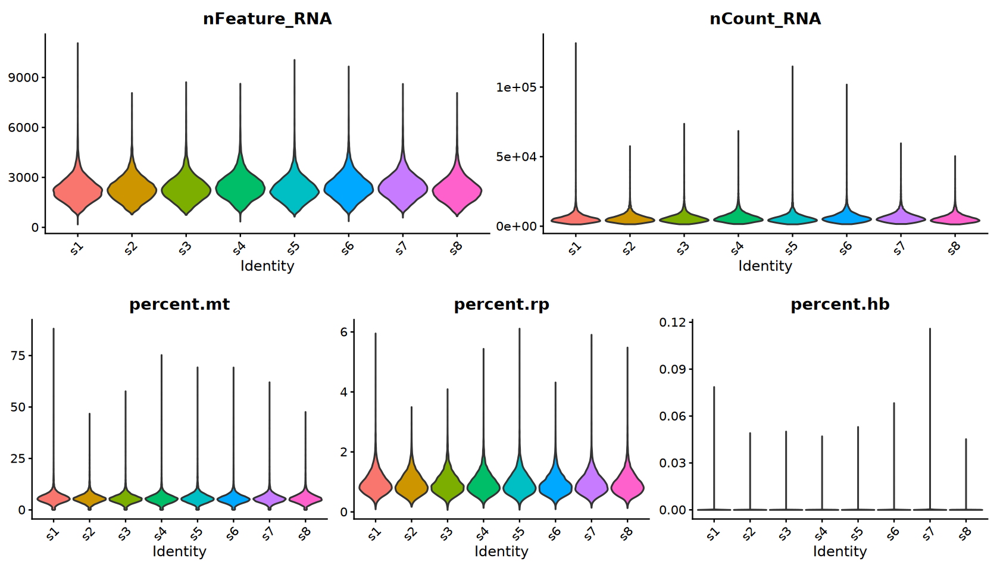

In [13]:
# Visualize QC metrics as a violin plot
p1 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("nFeature_RNA", "nCount_RNA"), 
    pt.size = 0, ncol = 2) & NoLegend()
p2 <- VlnPlot(
    sc.temp, layer = "counts", group.by = "orig.ident", 
    features = c("percent.mt", "percent.rp", "percent.hb"), 
    pt.size = 0, ncol = 3) & NoLegend()

options(repr.plot.width = 14, repr.plot.height = 8)
plot_grid(p1, p2, ncol = 1)

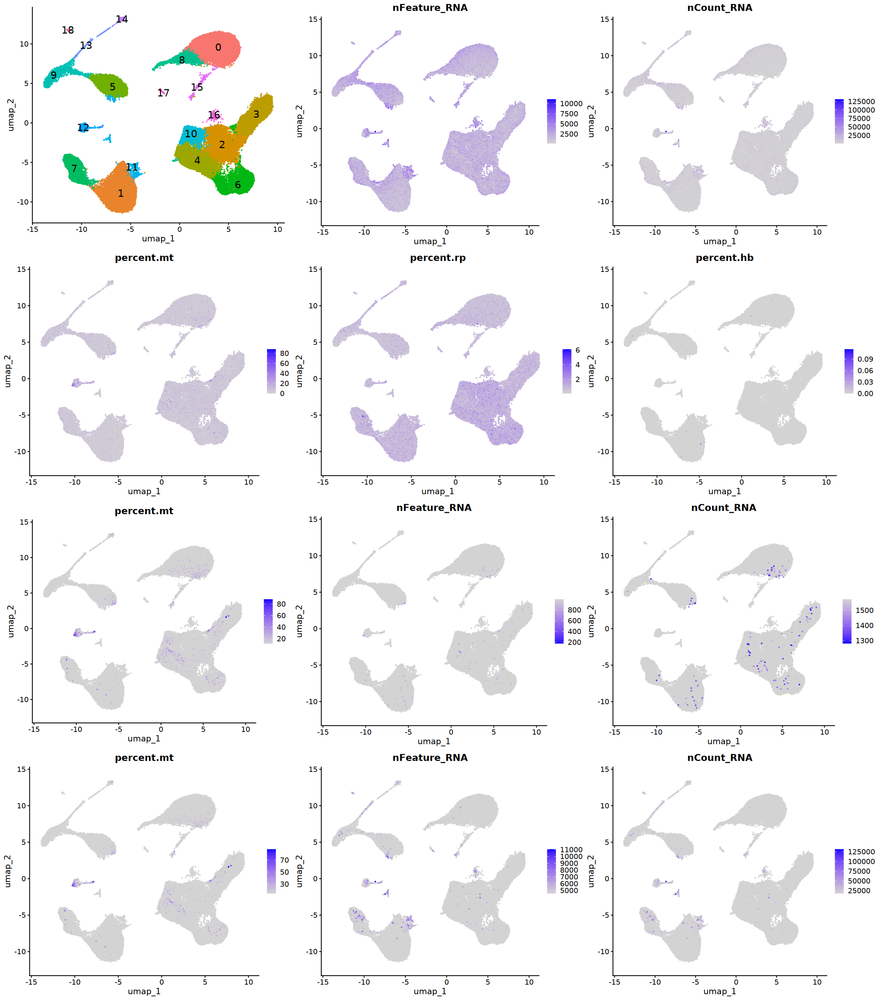

In [14]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p5 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4, p5), ncol = 3)

In [15]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA     nCount_RNA       percent.mt    
 Min.   :  176   Min.   :  1281   Min.   : 0.000  
 1st Qu.: 1847   1st Qu.:  3731   1st Qu.: 4.169  
 Median : 2293   Median :  5279   Median : 5.415  
 Mean   : 2358   Mean   :  5946   Mean   : 5.661  
 3rd Qu.: 2778   3rd Qu.:  7261   3rd Qu.: 6.766  
 Max.   :11057   Max.   :131536   Max.   :88.066  

In [16]:
source("R/calculate_mad_threshold.R")

In [17]:
nCount_threshold <- calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "both")
cat(sprintf("Counts: Lower: %d, Upper: %d\n", 
            nCount_threshold["lower_bound"],
            nCount_threshold["upper_bound"]))

nFeature_threshold <- calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "both")
cat(sprintf("Features: Lower: %d, Upper: %d\n", 
            nFeature_threshold["lower_bound"], 
            nFeature_threshold["upper_bound"]))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 3, sides = "upper")))

Counts: Lower: 1202, Upper: 23179
Features: Lower: 932, Upper: 5639
Mitochondrial: Upper: 16


## 3). Filtering Low-quality Cells

In [18]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 500 & 
        nCount_RNA > 1000 & nCount_RNA < 25000 & 
        percent.mt < 15 & percent.hb < 1)
scrna

An object of class Seurat 
33008 features across 66551 samples within 1 assay 
Active assay: RNA (33008 features, 0 variable features)
 1 layer present: counts

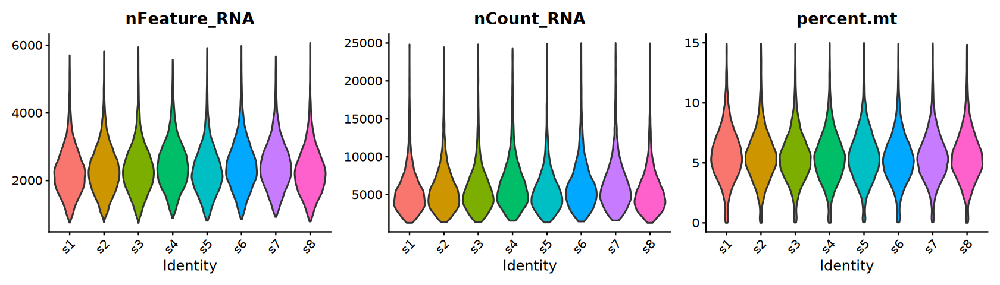

In [19]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident", 
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        pt.size = 0, ncol = 3) & NoLegend()

## 4). Evaluating Noise

### a). Cell cycle effect

In [20]:
calculate_cell_cycle_score <- function(
    obj, species = c("human", "mouse")) {

    species <- match.arg(species)

    cc_s <- switch(
        species,
        "human" = cc.genes$s.genes,
        "mouse" = stringr::str_to_title(cc.genes$s.genes),
        tolower(cc.genes$s.genes))
    
    cc_g2m <- switch(
        species,
        "human" = cc.genes$g2m.genes,
        "mouse" = stringr::str_to_title(cc.genes$g2m.genes),
        tolower(cc.genes$g2m.genes))
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        CellCycleScoring(s.features = cc_s, g2m.features = cc_g2m, 
                         set.ident = FALSE)

    return(obj)
}

In [21]:
scrna <- calculate_cell_cycle_score(scrna, species = "human")

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

In [22]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")

In [23]:
calculate_dissociation_score <- function(
    obj, species = c("human", "mouse")) {
    
    species <- match.arg(species)

    diss_genes <- switch(
        species,
        "human" = toupper(dissociation_genes),
        "mouse" = dissociation_genes,
        tolower(dissociation_genes)
    )
    
    obj <- NormalizeData(obj, verbose = FALSE) |>
        AddModuleScore(name = "Dissociation.Score", 
                       features = list(dissociationGenes = diss_genes))
    obj@meta.data <- obj@meta.data |> 
        dplyr::rename("Dis.Score" = "Dissociation.Score1")
    
    return(obj)
}

In [24]:
scrna <- calculate_dissociation_score(scrna, species = "human")

Warning message:
“The following features are not present in the object: FAM132B, MT1, MT2, CCRN4L, not searching for symbol synonyms”


### c). Batch effect

In [25]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

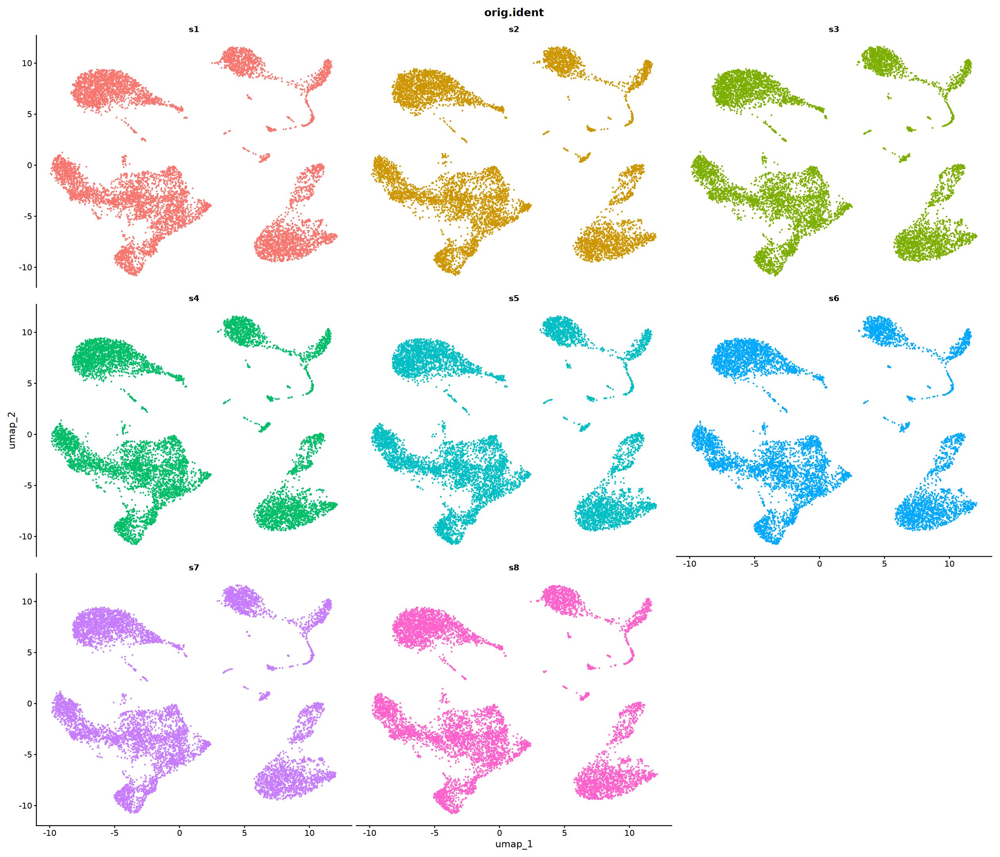

In [26]:
options(repr.plot.width = 21, repr.plot.height = 18)
DimPlot(sc.temp, reduction = "umap", group.by = "orig.ident", 
        split.by = "orig.ident", ncol = 3) & NoLegend()

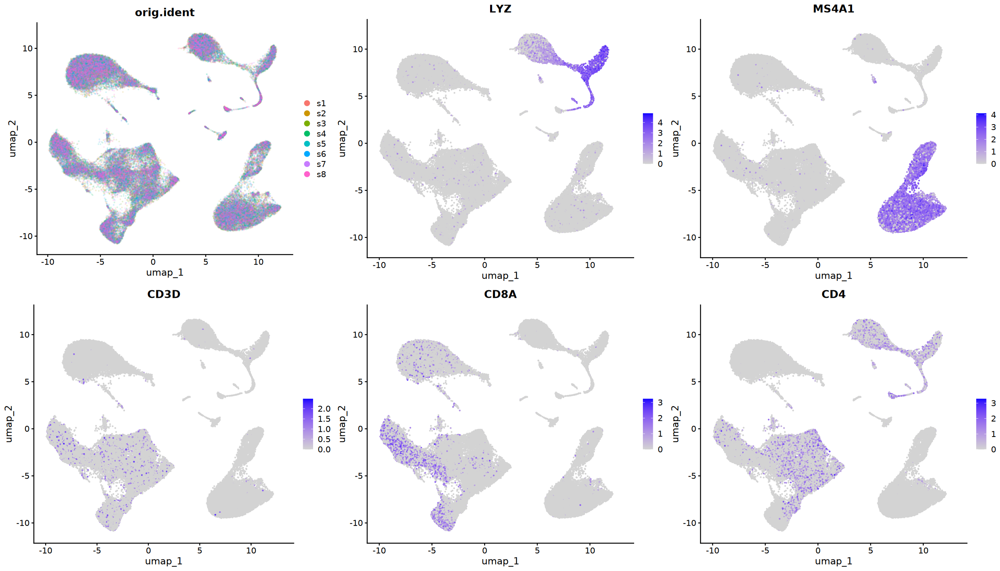

In [27]:
geneset <- c("LYZ", "MS4A1", "CD3D", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident",
    pt.size = 0.1, alpha = 0.1, label = FALSE)
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

# 3. Initial Assessment

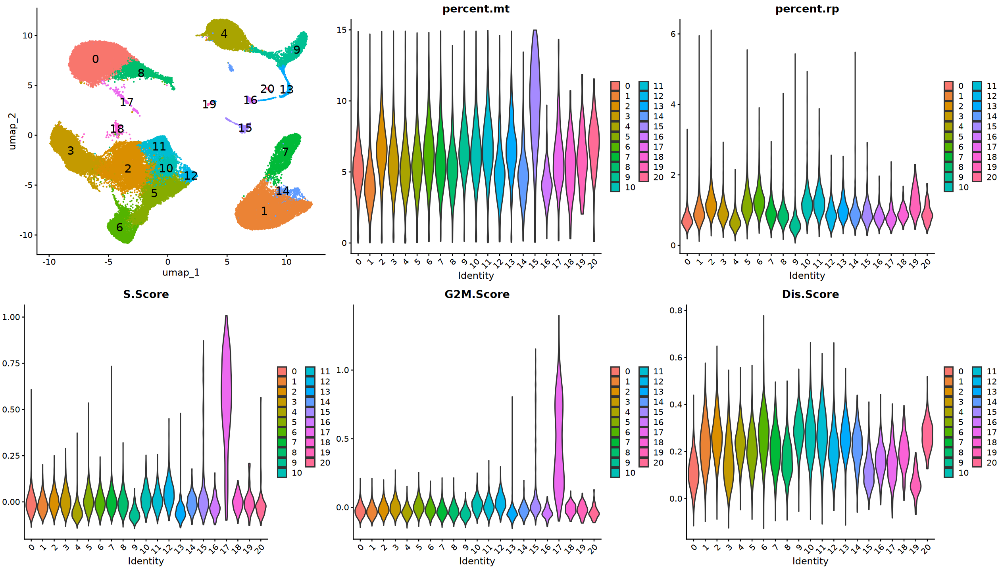

In [28]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

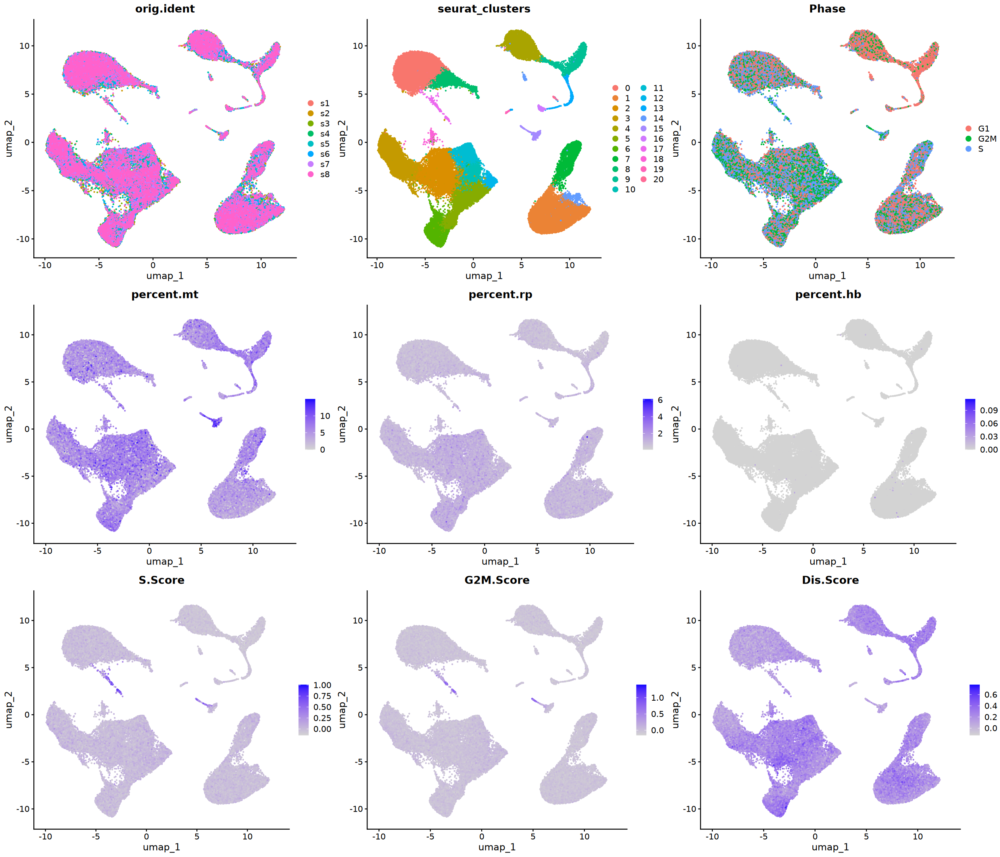

In [29]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

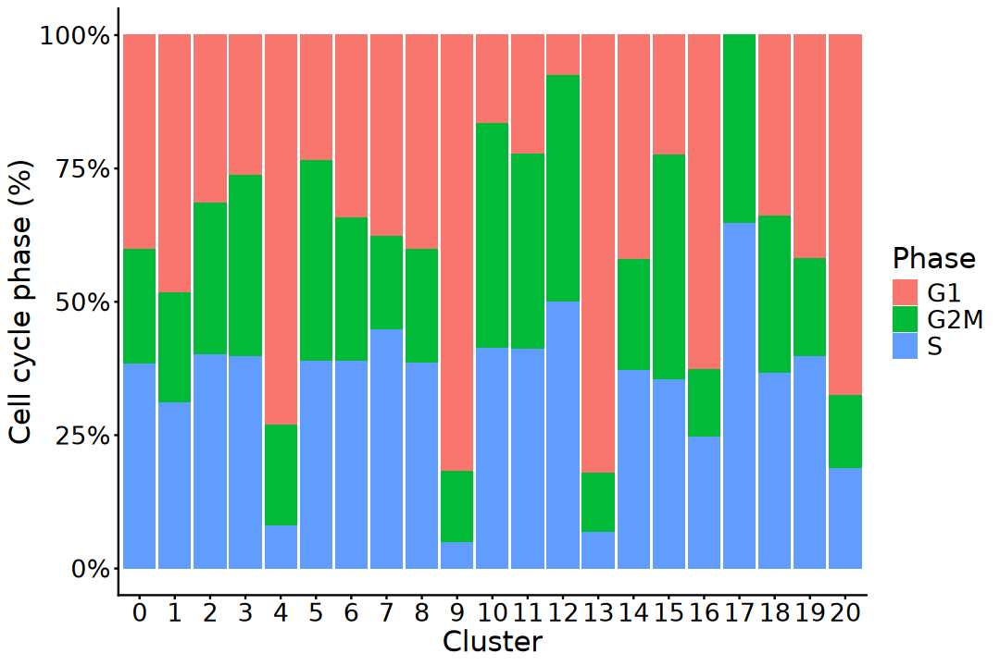

In [30]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [31]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

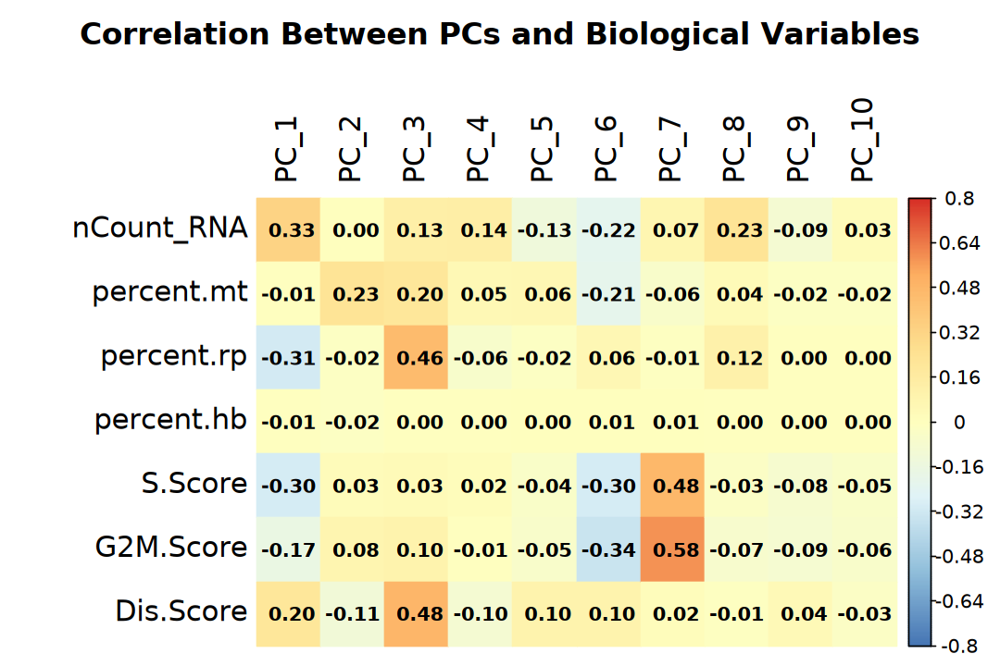

In [32]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-.8, .8),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [33]:
scrna <- NormalizeData(scrna, verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 3000, verbose = FALSE) |>
    ScaleData(vars.to.regress = "percent.mt", verbose = FALSE)
scrna

An object of class Seurat 
33008 features across 66551 samples within 1 assay 
Active assay: RNA (33008 features, 3000 variable features)
 3 layers present: counts, data, scale.data

# 5. Linear Dimensionality Reduction

In [34]:
scrna <- RunPCA(scrna, npcs = 50, verbose = FALSE)

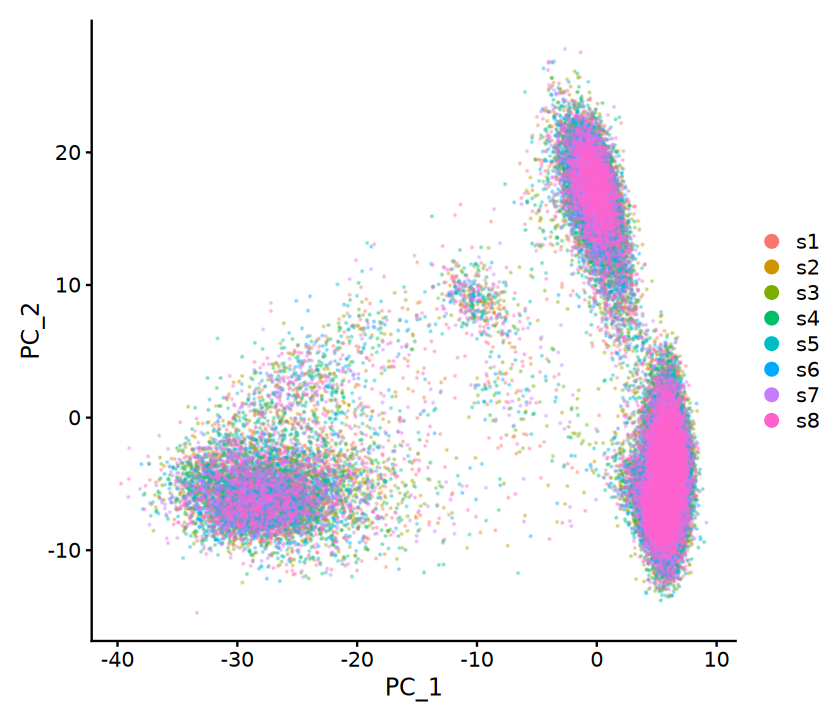

In [35]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(scrna, reduction = "pca", alpha = 0.3)

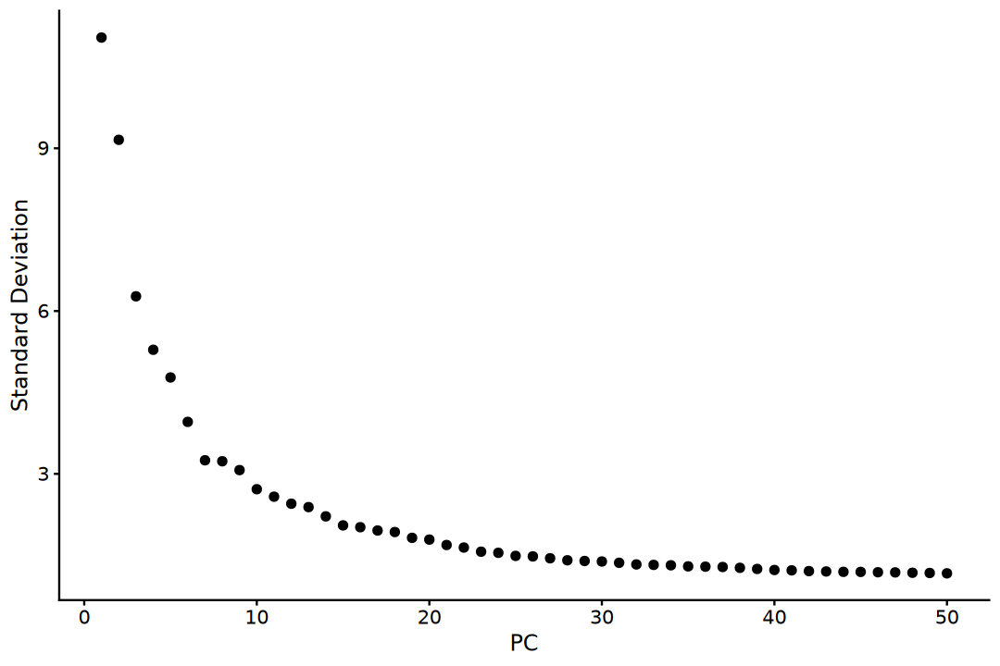

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(scrna, ndims = 50)

In [37]:
# Estimating PCA dimensionality
pca_var <- scrna@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 24


In [38]:
source("R/compare_npcs_clustering.R")

In [39]:
plots <- compare_npcs_clustering(
    scrna, reduction = "pca", method = "umap")

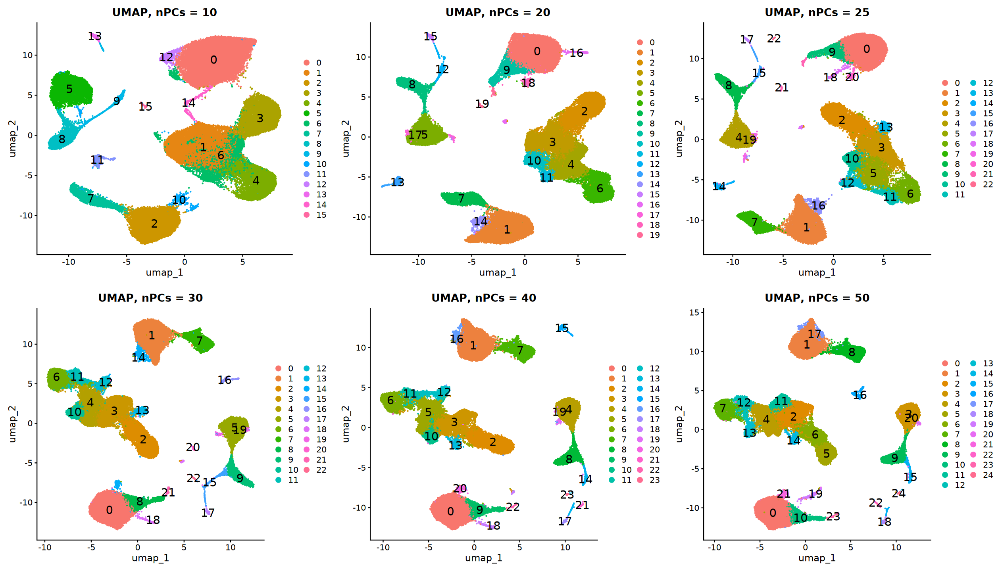

In [40]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plots, ncol = 3)

In [41]:
nPCs <- 30

# 6. Integration (Skip)

# 7. Neighborhood Graph Construction

In [42]:
scrna <- FindNeighbors(
    scrna, k.param = 20, reduction = "pca", 
    dims = 1:nPCs, verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [43]:
scrna <- RunUMAP(
    scrna, dims = 1:nPCs, reduction = "pca", 
    verbose = FALSE)

In [44]:
scrna <- RunTSNE(
    scrna, dims = 1:nPCs, reduction = "pca",
    verbose = FALSE)

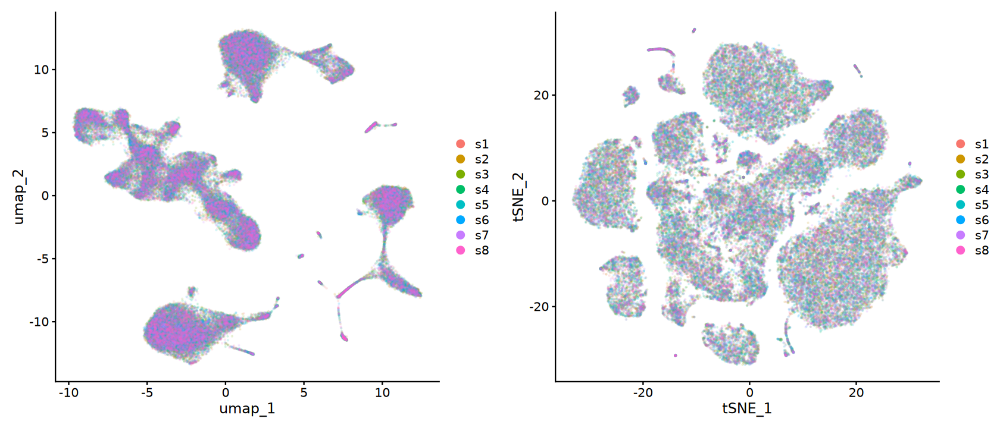

In [45]:
p1 <- DimPlot(
    scrna, reduction = "umap", pt.size = 0.1, alpha = 0.1)
p2 <- DimPlot(
    scrna, reduction = "tsne", pt.size = 0.1, alpha = 0.1)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [46]:
source("R/scan_clustering_resolution.R")

In [47]:
cluster_list <- scan_clustering_resolution(
    scrna, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1), assess = FALSE)

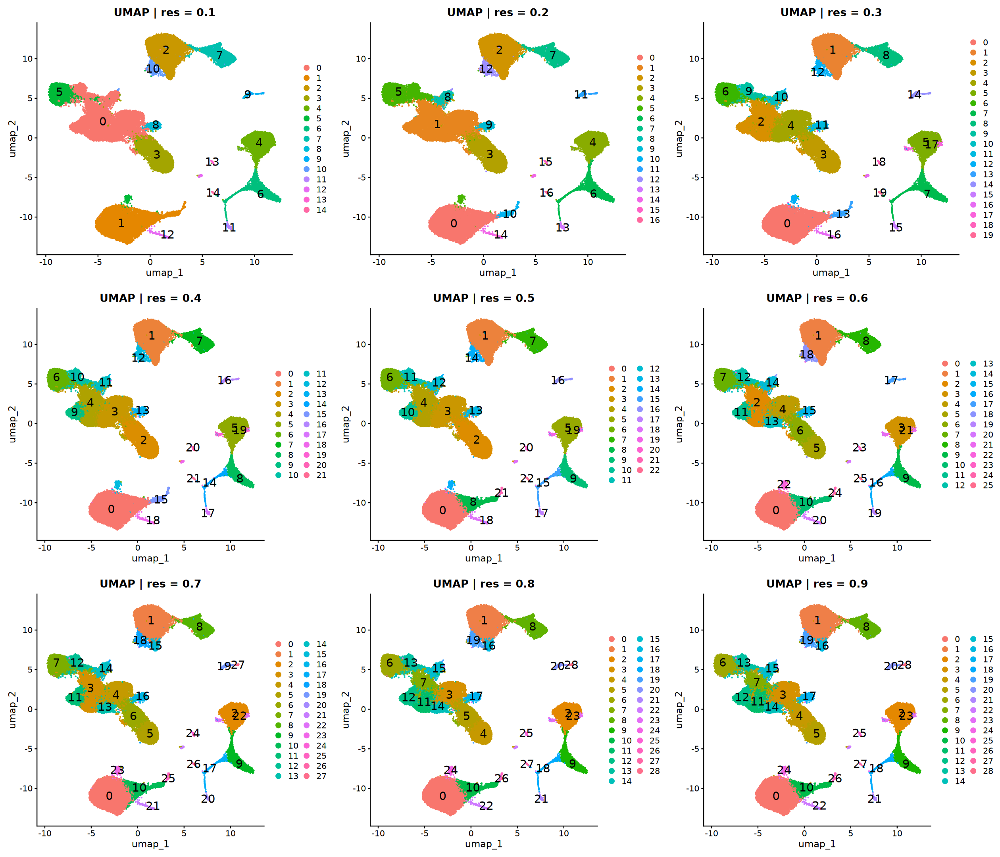

In [48]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

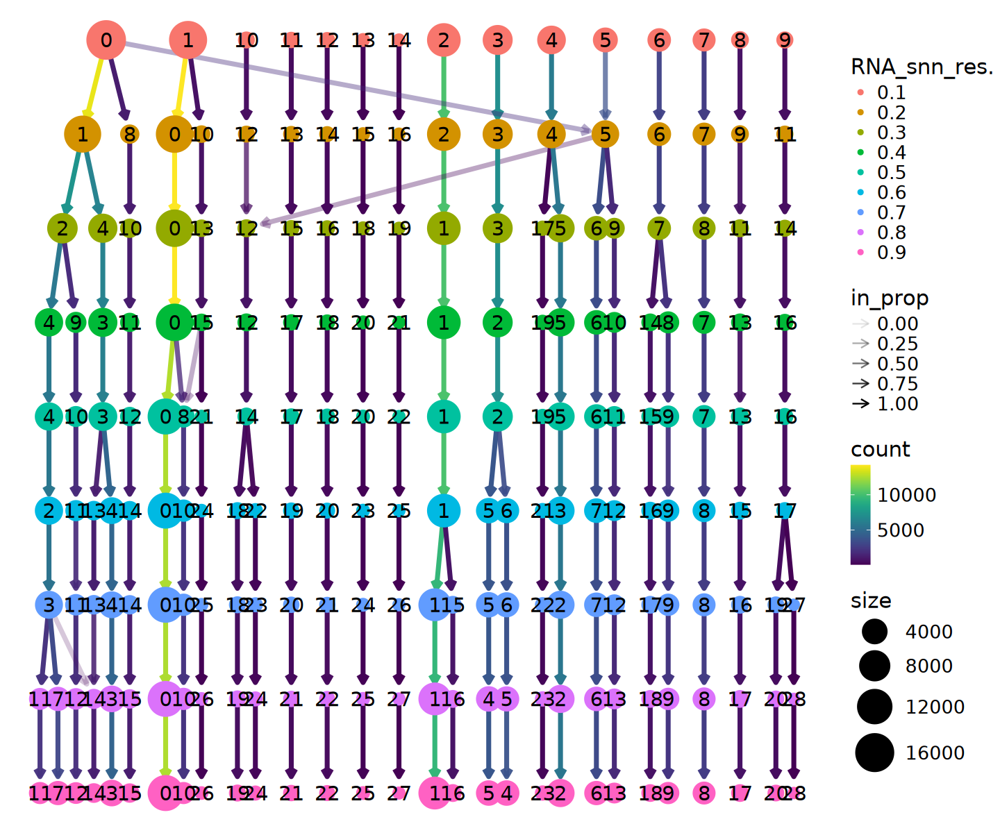

In [49]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [50]:
scrna <- FindClusters(
    scrna, resolution = 0.7, verbose = FALSE)

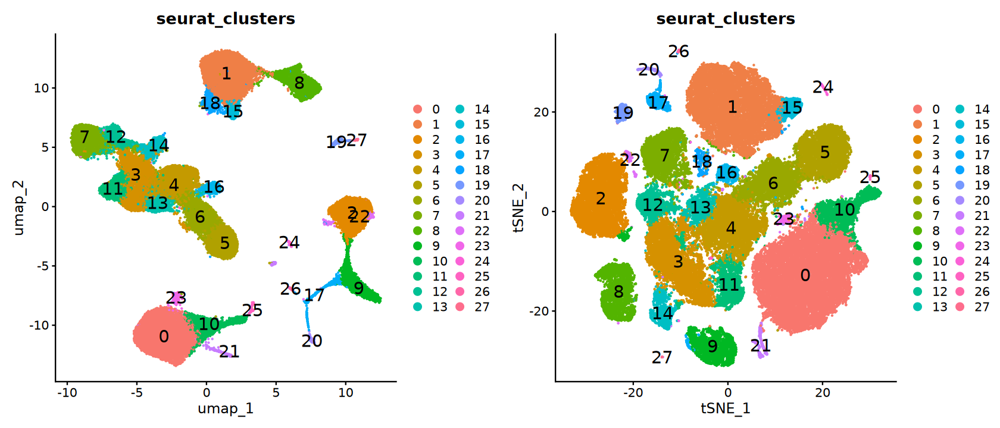

In [51]:
p1 <- DimPlot(
    scrna, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)
p2 <- DimPlot(
    scrna, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

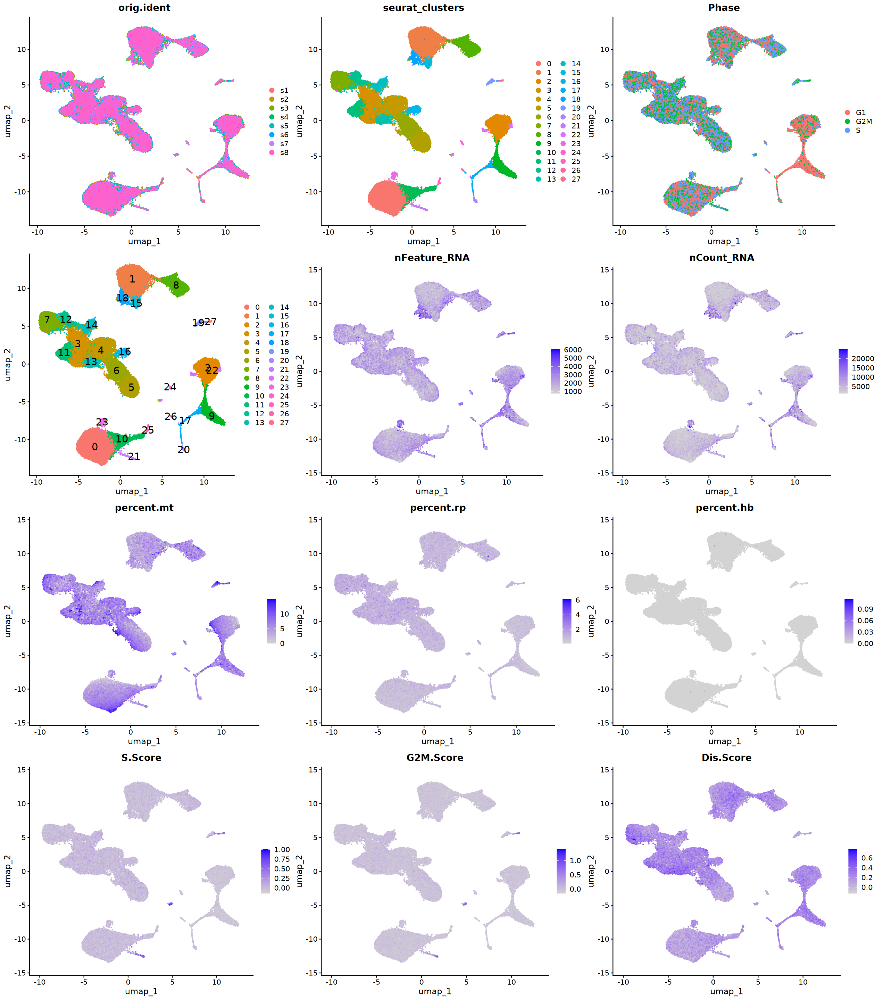

In [52]:
p1 <- DimPlot(
    scrna, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- DimPlot(
    scrna, reduction = "umap", combine = FALSE,
    label = TRUE, label.size = 6)
p3 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [53]:
scrna

An object of class Seurat 
33008 features across 66551 samples within 1 assay 
Active assay: RNA (33008 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 3 dimensional reductions calculated: pca, umap, tsne

# 10. Cluster Biomarkers

In [54]:
sc.markers <- FindAllMarkers(
    scrna, logfc.threshold = log2(1.2), 
    min.pct = 0.25, verbose = FALSE)

In [55]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [56]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,⋯,18,19,20,21,22,23,24,25,26,27
length(gene),238,294,1057,149,138,108,78,200,357,986,⋯,499,1500,1500,1087,922,884,1533,147,1507,2147


In [57]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

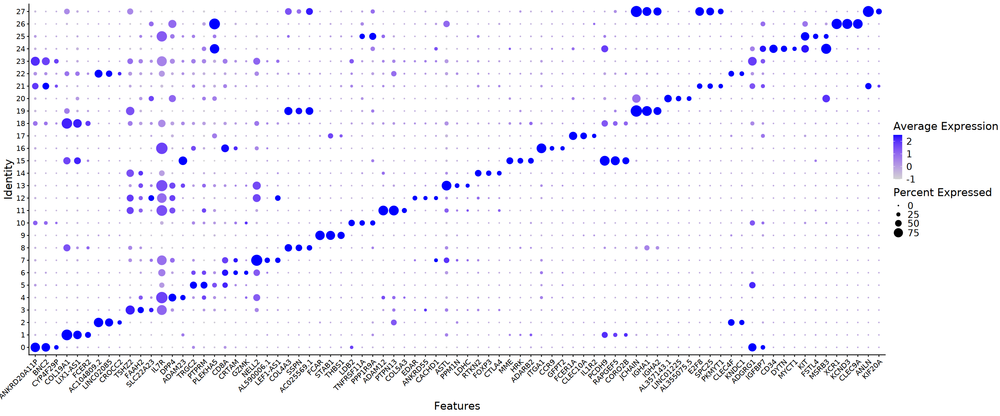

In [58]:
options(repr.plot.width = 24, repr.plot.height = 10)
DotPlot(scrna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [59]:
# plot_dir <- file.path(
#     data_dir, "visualization", "p7.1_cluster_top10_genes")

# if (!dir.exists(plot_dir)) {
#     dir.create(plot_dir, recursive = TRUE)
# }

In [60]:
# for (index in seq(1:length(top10$gene))) {
#     p1 <- VlnPlot(scrna, features = top10$gene[index])
#     p2 <- FeaturePlot(
#         scrna, reduction = "umap", features = top10$gene[index])
#     p3 <- FeaturePlot(
#         scrna, reduction = "tsne", features = top10$gene[index])
#     pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
#     file.path(plot_dir, paste0(
#         "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
#         ggsave(plot = pg, width = 9, height = 8)
# }

In [61]:
# ht <- DoHeatmap(scrna, features = top3$gene, 
#                 slot = "scale.data", size = 8) +
#     # scale_fill_gradientn(colors = PurpleAndYellow()) +
#     theme(axis.text = element_text(size = 12),
#           legend.title = element_text(size = 18), 
#           legend.text = element_text(size = 16))

# file.path(data_dir, "visualization", "p7.2_DEG_Top3_DoHeatmap.png") |>
#     ggsave(plot = ht, width = 24, height = 16)

# 11. Cell-type Annotation

## a). Automatic

In [62]:
suppressPackageStartupMessages(library(SingleR))
suppressPackageStartupMessages(library(SingleCellExperiment))

In [63]:
ref_pbmc <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "matrix", "RNA_3P", "RNA") |>
    Read10X()

In [64]:
ref_metadata <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    select(celltype.l1, celltype.l2, celltype.l3)

In [65]:
ref_pbmc <- SingleCellExperiment(
    list(counts = ref_pbmc), 
    colData = ref_metadata)

ref_pbmc <- scuttle::logNormCounts(ref_pbmc)

ref_pbmc

class: SingleCellExperiment 
dim: 33538 161764 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(161764): L1_AAACCCAAGAAACTCA L1_AAACCCAAGACATACA ...
  E2L8_TTTGTTGGTTGGCTAT E2L8_TTTGTTGTCTCATGGA
colData names(4): celltype.l1 celltype.l2 celltype.l3 sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [66]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l2, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

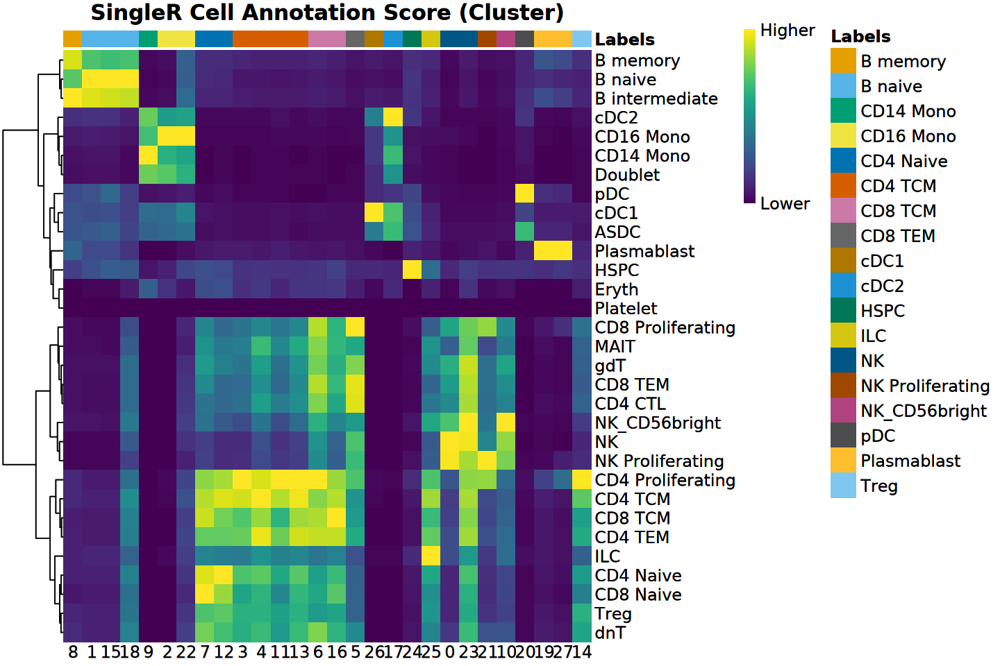

In [67]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [68]:
scrna$celltype.SingleR <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

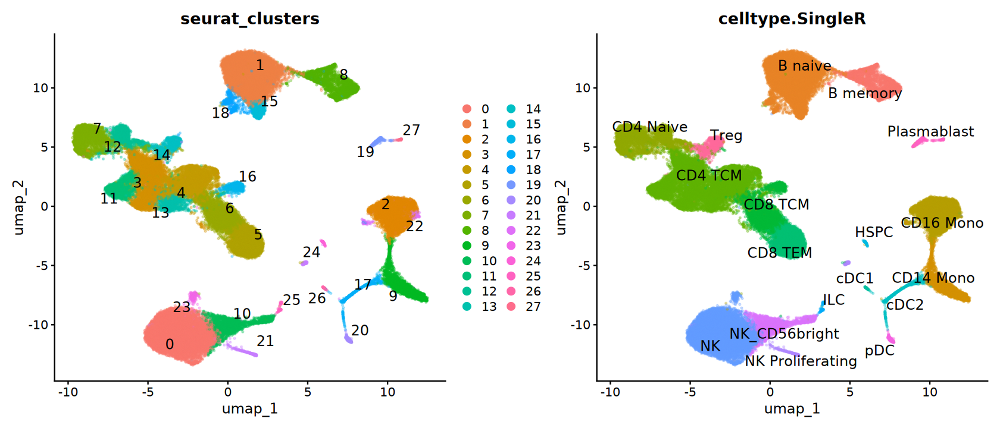

In [69]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimPlot(scrna, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) + 
    NoLegend()

## b). Manual

In [70]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [71]:
gene_list |> cat(sep = "\n")

cluster_0: "LINC00298", "ANKRD20A11P", "BNC2", "MYOM2", "LINGO2", "RNF165", "GZMB", "NME8", "CYP4F29P", "IGFBP7"
cluster_1: "FCRL1", "COL19A1", "CD22", "IGHD", "LIX1-AS1", "FCER2", "AP001636.3", "ABCB4", "CLEC17A", "ZNF608"
cluster_2: "AC104809.2", "PAPSS2", "LINC02085", "SMIM25", "CLEC4F", "FAM20A", "LINC02432", "CDKN1C", "CROCC2", "HES4"
cluster_3: "TSHZ2", "CD28", "FMN1", "ICOS", "FAAH2", "CMTM8", "IGSF9B", "SLC22A23", "ST8SIA1", "C15orf53"
cluster_4: "IL7R", "ANK3", "RASGRF2", "DPP4", "BTBD11", "LRIG1", "ADAM23", "TSPAN18", "KIF5C", "FAM19A1"
cluster_5: "TRGC2", "MIAT", "PTPRM", "KLRG1", "PATL2", "MSC-AS1", "CD8A", "PLEKHA5", "AC010175.1", "TPRG1"
cluster_6: "MCOLN2", "CD8A", "MVB12B", "IFNG-AS1", "CD84", "CRTAM", "GZMK", "MSC-AS1", "TPRG1", "ST8SIA1"
cluster_7: "NELL2", "LEF1", "ACTN1", "AL590006.1", "LEF1-AS1", "PLXNA4", "SH3RF3", "CD8B", "SIRPG", "SLC16A10"
cluster_8: "COL4A4", "COL4A3", "AL355076.2", "CD80", "TNFRSF13B", "SSPN", "AC025569.1", "SOX5", "TFEC", "DNAH8"
cluster_9: 

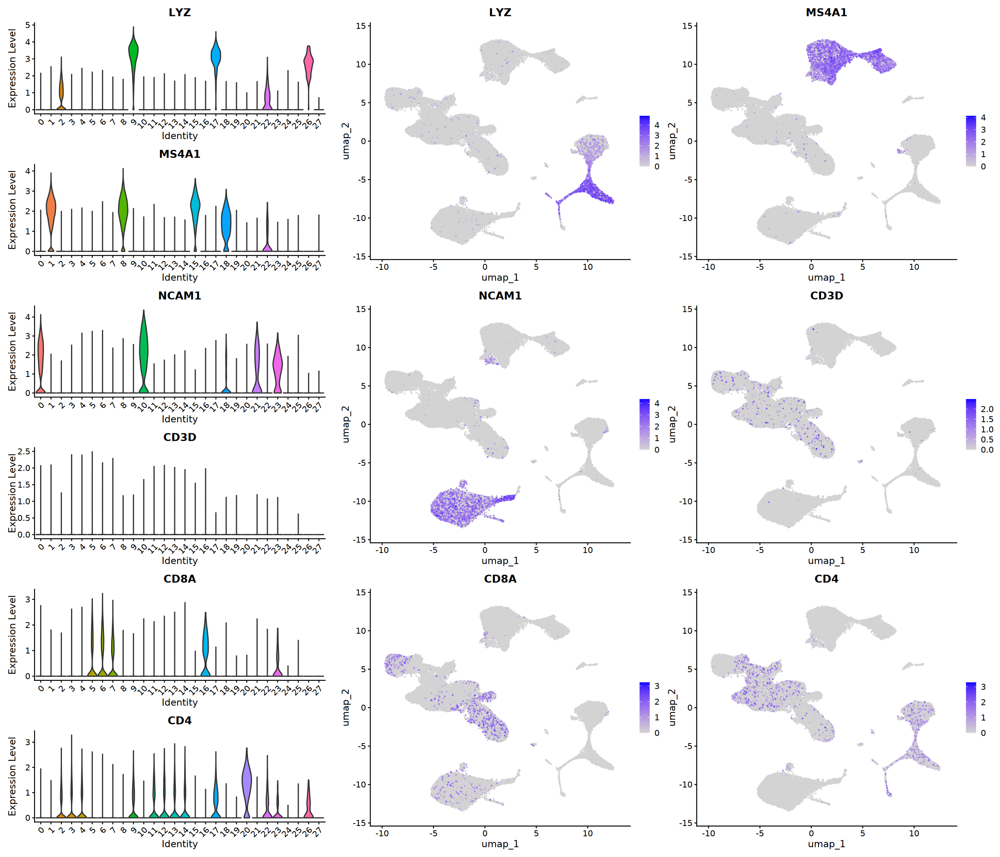

In [72]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 1, pt.size = 0)
p2 <- FeaturePlot(
    scrna, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(p1, p2, ncol = 2, rel_widths = c(1, 2))

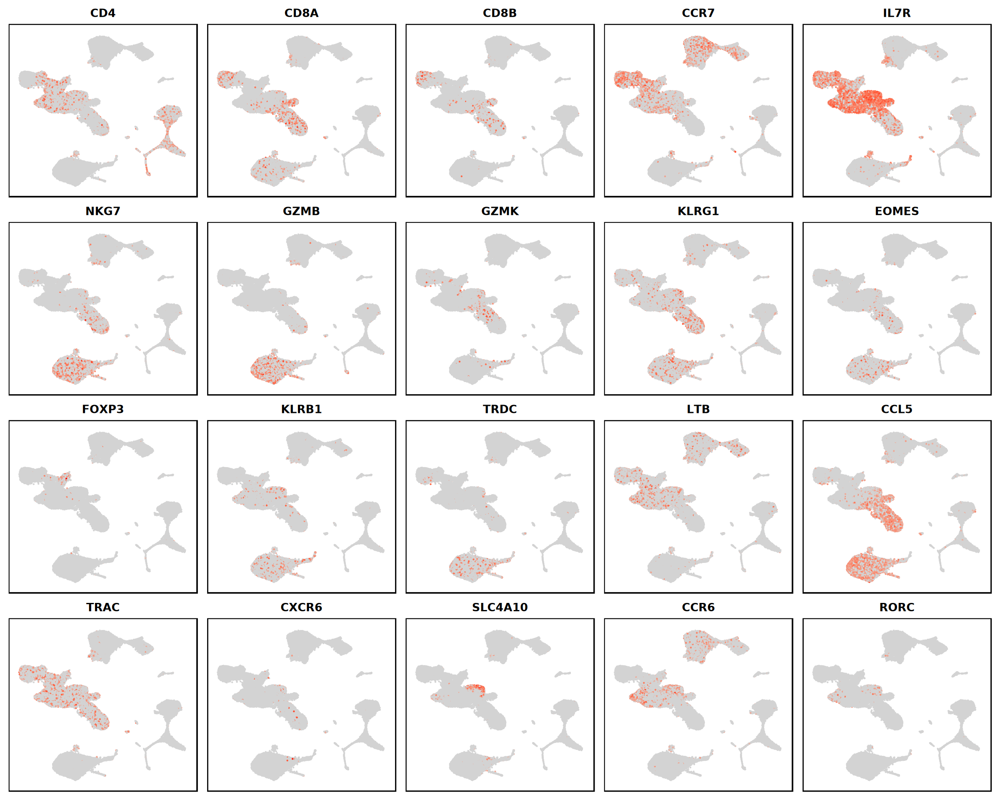

In [73]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5",
             "TRAC", "CXCR6", "SLC4A10", "CCR6", "RORC")

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

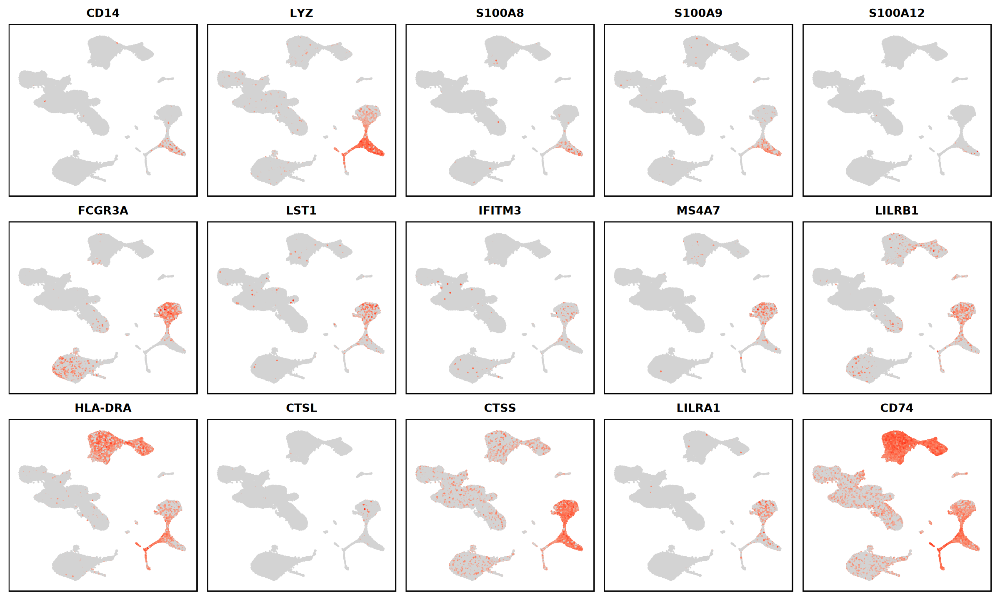

In [74]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

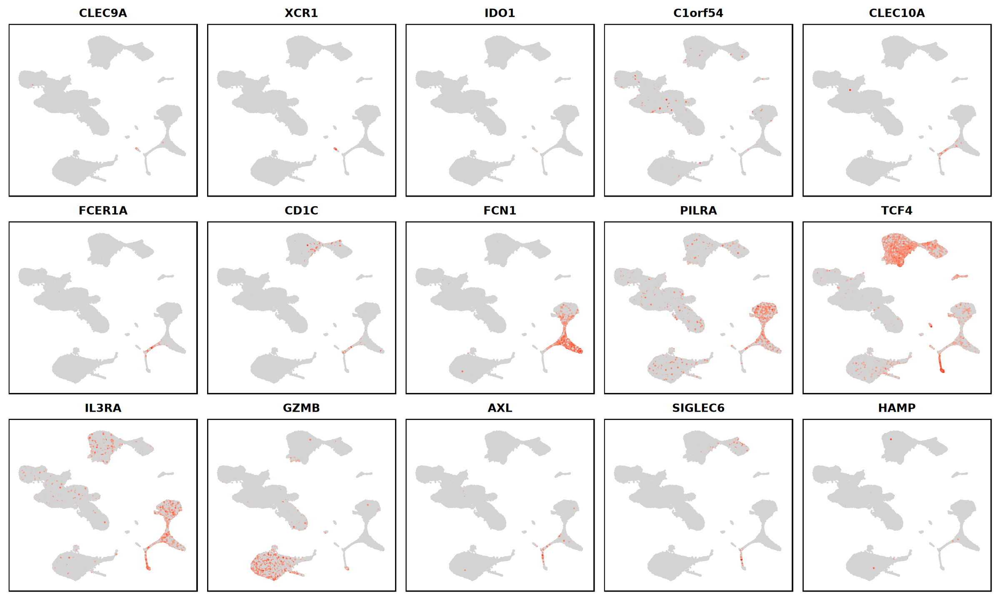

In [75]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "GZMB", "TCF4", "IL3RA", "CLEC4C"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CLEC10A", "FCER1A", "CD1C", "FCN1", "PILRA",
             "TCF4", "IL3RA", "GZMB",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

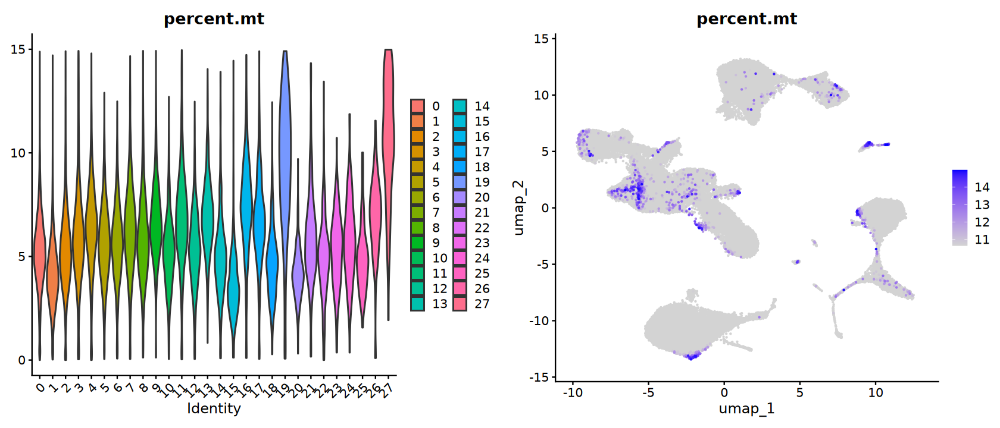

In [76]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 <- VlnPlot(
    scrna, features = "percent.mt", pt.size = 0)
p2 <- FeaturePlot(
    scrna, reduction = "umap", features = "percent.mt",
    min.cutoff = "q98", order = TRUE)

plot_grid(plotlist = c(p1, p2), ncol = 2)

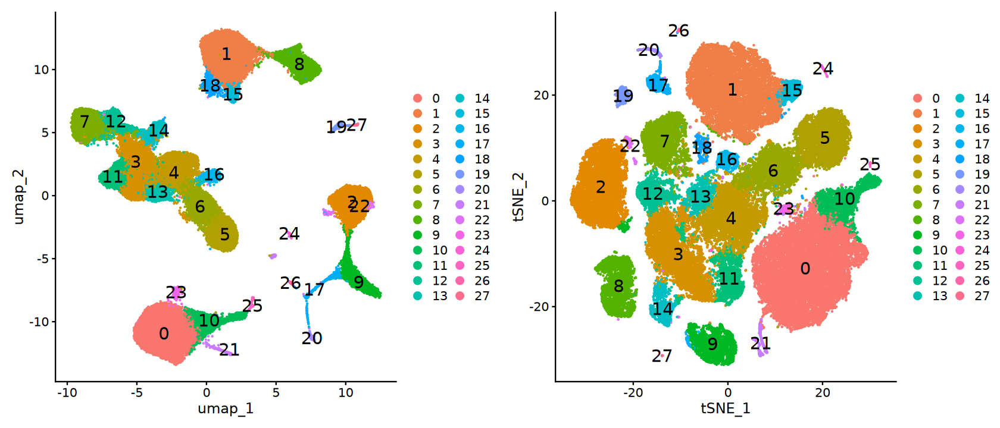

In [77]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [78]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "NK Cells", "1" = "Naïve B", "2" = "Non-classical Monocytes",
    "3" = "Activated CD4 T", "4" = "Activated CD4 T", "5" = "Cytotoxic CD8 T",
    "6" = "Cytotoxic CD8 T", "7" = "Naïve CD8 T", "8" = "Memory B",
    "9" = "Classical monocytes", "10" = "NK Cells", "11" = "Activated CD4 T",
    "12" = "Naïve CD4 T", "13" = "Activated CD4 T", "14" = "Treg",
    "15" = "Naïve B", "16" = "Memory CD8 T", "17" = "cDC2",
    "18" = "Naïve B", "19" = "Plasmablast", "20" = "pDC",
    "21" = "Proliferating", "22" = "Non-classical Monocytes", "23" = "NK Cells",
    "24" = "HSPC", "25" = "NK Cells", "26" = "cDC1", 
    "27" = "Plasmablast")

In [79]:
# Cell annotation with ChatGPT assistance
group2celltype <- c(
    "0" = "NK", "1" = "B", "2" = "Myeloids",
    "3" = "T", "4" = "T", "5" = "T",
    "6" = "T", "7" = "T", "8" = "B",
    "9" = "Myeloids", "10" = "NK", "11" = "T",
    "12" = "T", "13" = "T", "14" = "T",
    "15" = "B", "16" = "T", "17" = "Myeloids",
    "18" = "B", "19" = "Plasmablast", "20" = "Myeloids",
    "21" = "Proliferating", "22" = "Myeloids", "23" = "NK",
    "24" = "HSPC", "25" = "NK", "26" = "Myeloids", 
    "27" = "Plasmablast")

In [80]:
scrna@meta.data$celltype <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]
scrna@meta.data$grouptype <- 
    group2celltype[as.character(scrna$seurat_clusters)]

scrna <- RenameIdents(scrna, cluster2celltype)

Warning message:
“ggrepel: 1 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


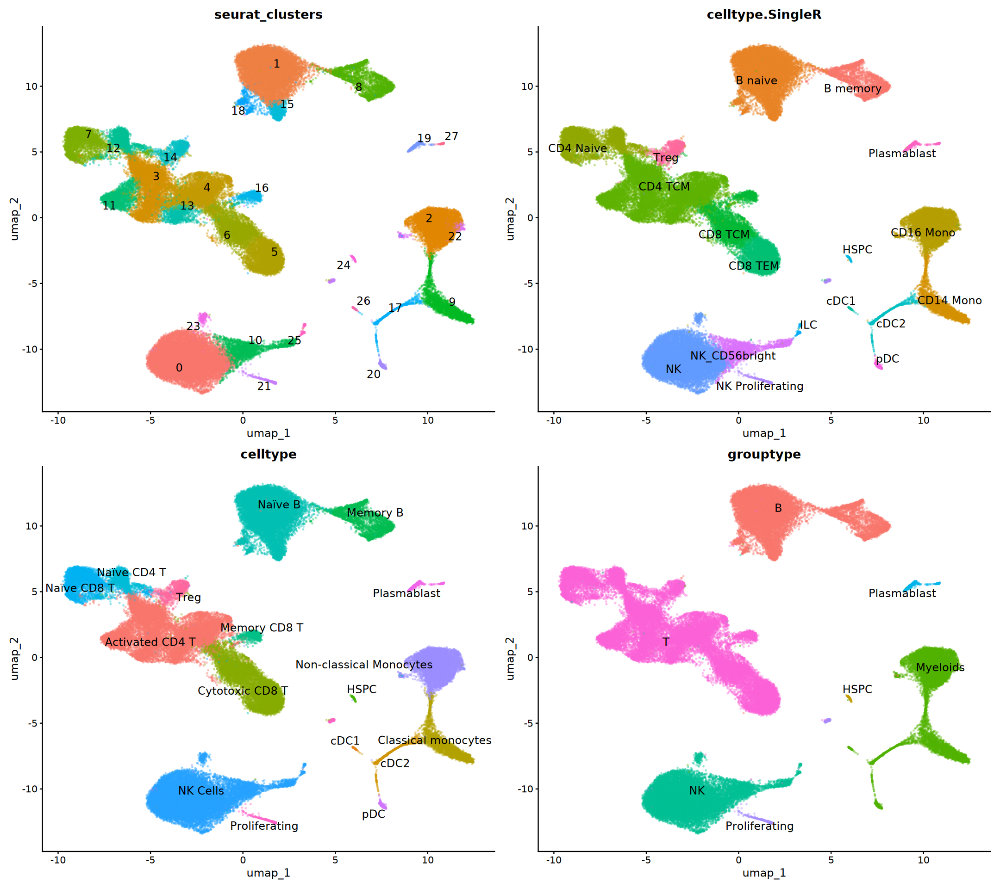

In [81]:
options(repr.plot.width = 18, repr.plot.height = 16)
DimPlot(scrna, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR",
                     "celltype", "grouptype"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) & 
    NoLegend()

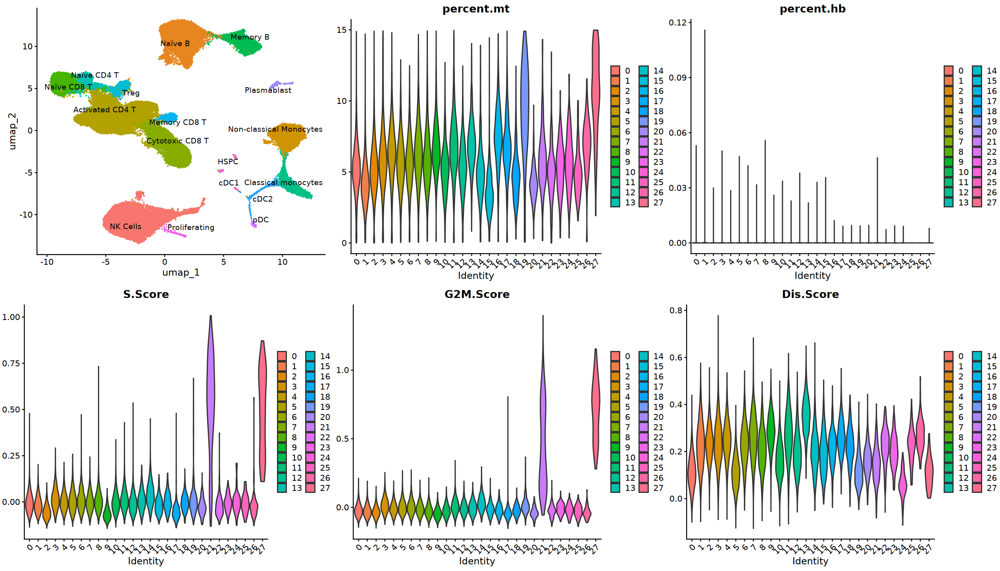

In [82]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- VlnPlot(
    scrna, features = c("percent.mt", "percent.hb"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    scrna, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

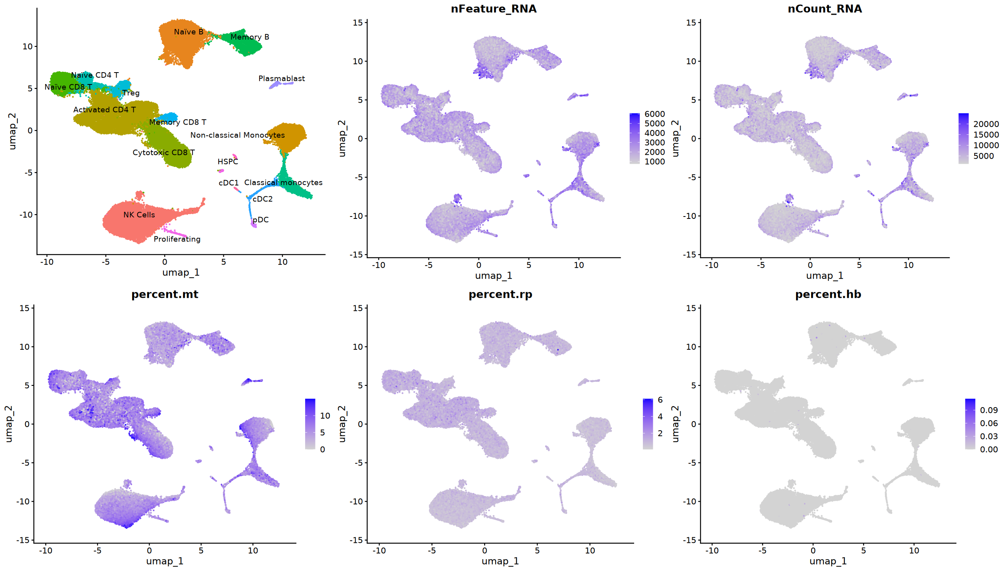

In [83]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [84]:
qs2::qs_save(scrna, file.path(
    data_dir, "result", "s11_annotation_seurat_V5.qs2"))